# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Logistic Regression
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 13th October 2026*

---

## Research question

**Can the time of day help predict which of my ten most-listened-to artists I will listen to?**

This notebook uses Last.fm scrobbles to test whether listening time contains a useful signal about artist choice. 

It first treats artist as a ten-class prediction problem, then looks more closely at the probability of listening to Tame Impala by hour.

The analysis is limited to my ten most-scrobbled artists and uses time of day as the model feature

```%pip install pandas scikit-learn matplotlib```

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
scrobbles = pd.read_csv('datasets/scrobbles.csv')

## Define the artist set

Ten artists with the highest scrobble counts are selected and displayed in the table below shows their listening counts and how their share varies across the four time-of-day categories.

**Question:** Are some of these artists more common at particular times of day?

In [2]:
top_artists = scrobbles['artist'].value_counts().head(10).index
subset = scrobbles[scrobbles['artist'].isin(top_artists)].copy()

print(subset['artist'].value_counts())
print(pd.crosstab(subset['tod'], subset['artist'], normalize='index').round(2))

artist
Arctic Monkeys           2230
Tame Impala              2042
Red Hot Chili Peppers    1559
Portishead               1199
Alice in Chains          1108
John Mayer                892
Ghost                     572
Morcheeba                 562
Pink Floyd                509
Massive Attack            500
Name: count, dtype: int64
artist     Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
tod                                                                             
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
morning               0.12            0.11   0.11        0.02            0.08   
night                 0.06            0.27   0.00        0.14            0.02   

artist     Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
tod                                                                   
afternoon       0.03        0.04      

I encode `tod` as one-hot features and use the artist name as the target. The data is split into training and test sets, preserving each artist's share in both sets (`stratify=y`).

I compare the model's test accuracy with a simple baseline that always predicts the most common artist in the training data. The classification report also shows precision, recall, and F1-score for each artist, which helps reveal whether accuracy hides poor results for less frequent artists.

In [3]:
# get dummies referenced from https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/03.10-Working-With-Strings.ipynb
X = pd.get_dummies(subset['tod']).astype(int)
y = subset['artist']

# Train/test evaluation follows the workflow in PythonDataScienceHandbook/notebooks/05.03-Hyperparameters-and-Model-Validation.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# The estimator fit/predict pattern follows PythonDataScienceHandbook/notebooks/05.02-Introducing-Scikit-Learn.ipynb
# LogisticRegression is used here for this Last.fm multiclass prediction task
clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

baseline = y_train.value_counts().idxmax()
print('Baseline accuracy:', accuracy_score(y_test, [baseline] * len(y_test)))
print('Model accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Baseline accuracy: 0.19955257270693513
Model accuracy: 0.23355704697986576
                       precision    recall  f1-score   support

      Alice in Chains       0.00      0.00      0.00       222
       Arctic Monkeys       0.23      0.57      0.33       446
                Ghost       0.00      0.00      0.00       114
           John Mayer       0.00      0.00      0.00       178
       Massive Attack       0.00      0.00      0.00       100
            Morcheeba       0.00      0.00      0.00       112
           Pink Floyd       0.00      0.00      0.00       102
           Portishead       0.00      0.00      0.00       240
Red Hot Chili Peppers       0.00      0.00      0.00       312
          Tame Impala       0.23      0.65      0.34       409

             accuracy                           0.23      2235
            macro avg       0.05      0.12      0.07      2235
         weighted avg       0.09      0.23      0.13      2235



### Multiclass result

The model reaches **23.4% test accuracy**, compared with **20.0%** for the most-common-artist baseline. That is a gain of about **3.4 percentage points**, so time of day adds only a small amount of predictive value overall.

The per-artist report gives a more important warning: the model has non-zero precision and recall for only Arctic Monkeys and Tame Impala, and scores zero for the other eight artists. The overall accuracy therefore overstates how useful the model is across the full set of artists.

**Takeaway:** time of day alone does not reliably identify which of the ten artists will be played. The probability table below shows the model's estimated distribution for each time category, rather than a dependable recommendation.

           Alice in Chains  Arctic Monkeys  Ghost  John Mayer  Massive Attack  \
morning               0.12            0.11   0.10        0.02            0.07   
afternoon             0.10            0.19   0.07        0.07            0.05   
evening               0.09            0.23   0.02        0.10            0.04   
night                 0.06            0.27   0.01        0.14            0.02   

           Morcheeba  Pink Floyd  Portishead  Red Hot Chili Peppers  \
morning         0.05        0.01        0.09                   0.11   
afternoon       0.03        0.04        0.08                   0.16   
evening         0.06        0.06        0.14                   0.14   
night           0.10        0.09        0.10                   0.04   

           Tame Impala  
morning           0.31  
afternoon         0.21  
evening           0.13  
night             0.17  


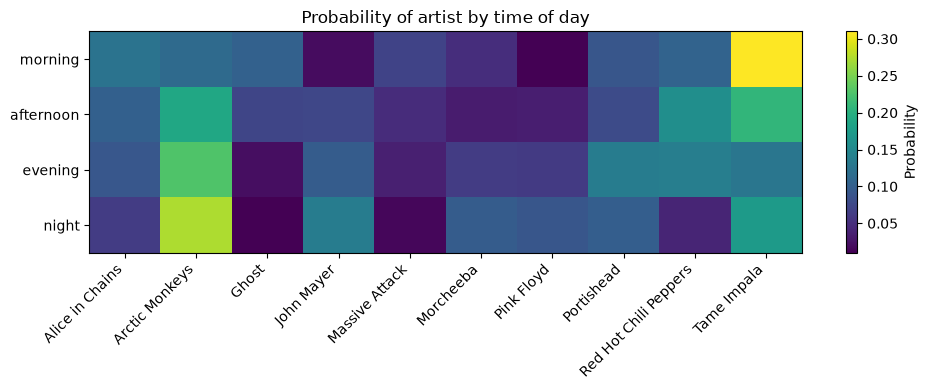

In [4]:
# Use predict_proba() from the fitted estimator (estimator API pattern in PythonDataScienceHandbook/notebooks/05.02-Introducing-Scikit-Learn.ipynb)
buckets = pd.DataFrame(np.eye(len(X.columns), dtype=int), columns=X.columns, index=X.columns)
probs = pd.DataFrame(clf.predict_proba(buckets), columns=clf.classes_, index=buckets.index)
probs = probs.reindex(['morning', 'afternoon', 'evening', 'night'])
print(probs.round(2))

fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(probs.values, aspect='auto')
ax.set_xticks(range(len(probs.columns)))
ax.set_xticklabels(probs.columns, rotation=45, ha='right')
ax.set_yticks(range(len(probs.index)))
ax.set_yticklabels(probs.index)
fig.colorbar(im, label='Probability')
ax.set_title('Probability of artist by time of day')
plt.tight_layout()
plt.show()

## Binary model: Tame Impala by hour

The multiclass model struggles to distinguish most artists, so this section asks a narrower question: **does the chance of listening to Tame Impala vary with the hour of day?**

The target is whether each scrobble is Tame Impala or another artist from the selected top ten. A binary logistic regression estimates that probability. ROC AUC measures how well it ranks Tame Impala scrobbles above the others; an AUC of 0.5 is chance-level ranking. The odds ratio summarizes how the modeled odds change with each one-hour step in the input feature.

Tame Impala AUC: 0.628
Odds ratio per hour: 0.894


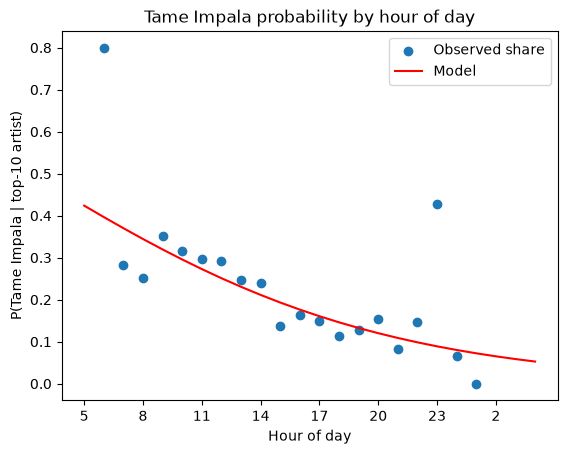

In [5]:
subset['hours_since_5'] = (subset['hour'] - 5) % 24
def artist_hour_model(artist_name):
    # Binary logistic regression: is this scrobble the chosen artist, given the hour
    data = subset.copy()
    data['is_target'] = (data['artist'] == artist_name).astype(int)

    X = data[['hours_since_5']]
    y = data['is_target']

    # Train/test evaluation follows PythonDataScienceHandbook/notebooks/05.03-Hyperparameters-and-Model-Validation.ipynb
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # LogisticRegression fit/predict_proba estimator pattern follows PythonDataScienceHandbook/notebooks/05.02-Introducing-Scikit-Learn.ipynb
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)

    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(artist_name, 'AUC:', round(auc, 3))
    print('Odds ratio per hour:', np.exp(model.coef_[0][0]).round(3))

    hrs = np.arange(0, 24)
    curve = model.predict_proba(pd.DataFrame({'hours_since_5': hrs}))[:, 1]
    observed = data.groupby('hours_since_5')['is_target'].mean()
    counts = data.groupby('hours_since_5').size()
    plt.scatter(observed.index, observed.values, label='Observed share')
    plt.plot(hrs, curve, color='red', label='Model')
    plt.xticks(range(0, 24, 3), [(h + 5) % 24 for h in range(0, 24, 3)])
    plt.xlabel('Hour of day')
    plt.ylabel(f'P({artist_name} | top-10 artist)')
    plt.title(f'{artist_name} probability by hour of day')
    plt.legend()
    plt.show()

artist_hour_model('Tame Impala')

## Overall conclusion

For the ten-class question, the model improves on the majority-artist baseline by only about 3.4 percentage points and fails to identify eight artists in the test set. Time of day alone is therefore a weak predictor of the specific artist.

For the narrower Tame Impala question, the model reports **ROC AUC = 0.628**, which is above chance but only modest separation. Its **0.894 odds ratio** indicates lower modeled odds with each one-hour step in `hours_since_5`. This feature is a linear sequence that wraps around the clock, however, so the odds ratio is only a rough trend and does not model time as truly cyclical.

**Answer to the research question:** listening time contains some signal, especially for a few artists, but it is not enough on its own to reliably predict artist choice. Day of week, listening history, or additional context could be tested as further features.